# 39 — Transformer tuning, second round: depth, width and training length

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extension 27. Notebook 07 changed the learning rate, the patch size, the data and the stem of the patch Transformer one lever at a time and found that none brought it to the CNN. Three levers were left: **depth** (6 blocks instead of 3), **width** (d = 128, MLP 256, 425 k parameters instead of 114 k) and **training length** (30 epochs instead of 12), all with fresh injections, patch 16, one seed, trained by `seq_models.py` (`tf16_d6_fresh`, `tf16_w128_fresh`, `tf16_long_fresh`). They are compared with the three seeds of the baseline (notebook 30) and with the CNN (five seeds): mean ρ₅₀ over the three morphologies at FAP 10⁻² and 10⁻³ with thresholds from the validation noise, and the validation loss.

**What it does not do.** One seed per variant (the seed scatter of the baseline Transformer is 0.05 at FAP 10⁻² and 0.2 at 10⁻³, notebook 30); no contrastive pre-training and no overlapping windows (the two remaining levers of the backlog were not run); the training budget is still that of a laptop.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, json, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seq_models as sm
import gwosc_tools as g
g.style()
CH, data, S1, DS = sm.load_data(); TEST = sm.make_test_sets(data, S1); SNRS = sm.SNRS; MORPHS = g.MORPHS
V = {"baseline (3 blocks, d=64, 12 ep.; 3 seeds)": [("tf16_fresh", s) for s in (0, 1, 2)], "depth 6 blocks": [("tf16_d6_fresh", 0)], "width d=128": [("tf16_w128_fresh", 0)], "30 epochs": [("tf16_long_fresh", 0)]}
def logits(m, x): return m.predict(sm.clip(x)[..., None], verbose=0, batch_size=1024)[:, 0]
fn = os.path.join(g.CACHE, "stats39.pkl")
if os.path.exists(fn): LG = pickle.load(open(fn, "rb"))
else:
    LG = {}
    for lab, lst in V.items():
        for name, s in lst:
            m = sm.train_variant(name, None, None, seed=s, verbose=False)[0]; d = {"val": logits(m, DS["val"]["noise"])}
            for k, (x, c) in TEST.items(): d[k] = logits(m, x)
            LG[(lab, s)] = d
    pickle.dump(LG, open(fn, "wb"))
hist = {lab: [json.load(open(os.path.join(sm.MODELS, f"v07_{n}_s{s}_hist.json"))) for n, s in lst] for lab, lst in V.items()}
params = {"baseline (3 blocks, d=64, 12 ep.; 3 seeds)": 114e3, "depth 6 blocks": 214e3, "width d=128": 425e3, "30 epochs": 114e3}
rows = []
for (lab, s), d in LG.items():
    for far in (1e-2, 1e-3):
        r = [g.bootstrap_rho(d["val"], [d[(k, x)] for x in SNRS], SNRS, far, B=100, seed=2) for k in MORPHS]
        rows.append(dict(variant=lab, seed=s, FAP=far, rho50=float(np.mean([np.nan_to_num(x[0][0], nan=16) for x in r])), err=float(np.sqrt(sum(((g.ci(x[1][:, 0])[1] - g.ci(x[1][:, 0])[0]) / 2) ** 2 for x in r)) / 3)))
R = pd.DataFrame(rows); T = R.groupby(["variant", "FAP"]).agg(rho50=("rho50", "mean"), seeds=("seed", "count"), test_err=("err", "mean")).unstack("FAP")
T["best_val_loss"] = [min(min(h["val_loss"]) for h in hist[v]) for v in T.index]; T["epochs"] = [int(np.mean([len(h["val_loss"]) for h in hist[v]])) for v in T.index]; T["parameters"] = [params[v] for v in T.index]; T.round(3)

rho50        seeds      test_err  \
FAP                                         0.001   0.01 0.001 0.01    0.001   
variant                                                                        
30 epochs                                   7.150  5.807     1    1    0.205   
baseline (3 blocks, d=64, 12 ep.; 3 seeds)  7.467  6.290     3    3    0.112   
depth 6 blocks                              7.208  6.232     1    1    0.105   
width d=128                                 6.969  6.106     1    1    0.130   

                                                  best_val_loss epochs  \
FAP                                          0.01                        
variant                                                                  
30 epochs                                   0.050         0.255     30   
baseline (3 blocks, d=64, 12 ep.; 3 seeds)  0.055         0.301     12   
depth 6 blocks                              0.057         0.299     12   
width d=128                                 0.053         0.301     12   

                                           parameters  
FAP                                                    
variant                                                
30 epochs                                    114000.0  
baseline (3 blocks, d=64, 12 ep.; 3 seeds)   114000.0  
depth 6 blocks                               214000.0  
width d=128                                  425000.0

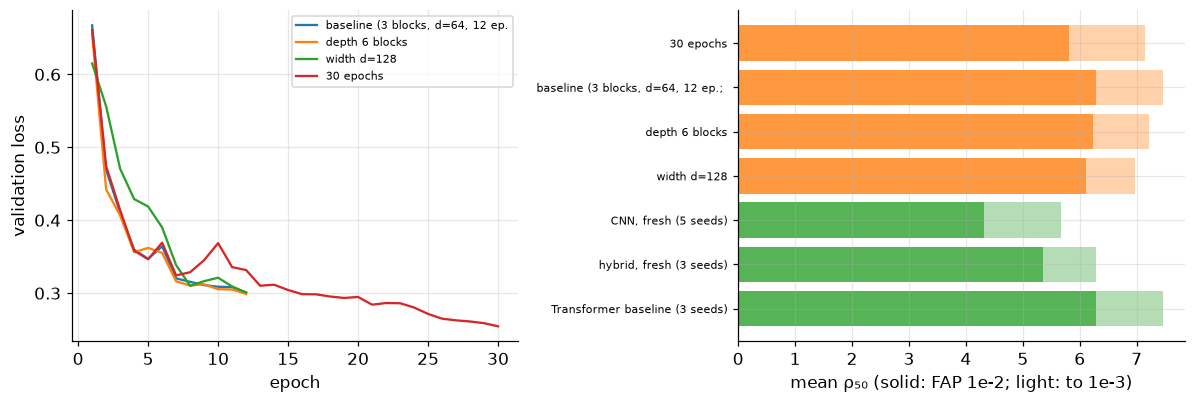

In [2]:
ref = {"CNN, fresh (5 seeds)": (4.31, 5.67), "hybrid, fresh (3 seeds)": (5.35, 6.29), "Transformer baseline (3 seeds)": (6.29, 7.47)}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for lab in V:
    ax[0].plot(range(1, 1 + len(hist[lab][0]["val_loss"])), hist[lab][0]["val_loss"], label=lab.split(";")[0])
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("validation loss"); ax[0].legend(fontsize=7)
lab_all = list(T.index) + list(ref); v2 = [T.loc[v, ("rho50", 0.01)] for v in T.index] + [x[0] for x in ref.values()]; v3 = [T.loc[v, ("rho50", 0.001)] for v in T.index] + [x[1] for x in ref.values()]
ax[1].barh(range(len(lab_all)), v2, color=["C1"] * len(T) + ["C2"] * len(ref), alpha=.8); ax[1].barh(range(len(lab_all)), np.array(v3) - np.array(v2), left=v2, color=["C1"] * len(T) + ["C2"] * len(ref), alpha=.35)
ax[1].set_yticks(range(len(lab_all))); ax[1].set_yticklabels([l[:34] for l in lab_all], fontsize=7); ax[1].invert_yaxis(); ax[1].set_xlabel("mean ρ₅₀ (solid: FAP 1e-2; light: to 1e-3)")
fig.tight_layout(); g.savefig(fig, "fig39_transformer_tuning"); plt.show()
TT = T.copy(); TT.columns = [f"{a}_{b}" if b != "" else a for a, b in TT.columns]; g.save_json(dict(rows=R.to_dict("records"), table=TT.reset_index().to_dict("records")), "39_summary.json")

## Output and next step

`results/39_summary.json`, `figures/fig39_transformer_tuning`. Next: the final slides.